In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)

data = pd.read_sql_query(
    "SELECT * FROM agri_yield_train",
    conn
)

conn.close()

X = data.drop(columns=["yield"])
X = X.select_dtypes(include="number")

y = data["yield"]

print("Dataset shape:", data.shape)
print("Features used:", X.columns.tolist())
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (10000, 9)
Features used: ['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']
Feature shape: (10000, 7)
Target shape: (10000,)


In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

predictions = {}
results = []

for name, model in models.items():

    y_pred = cross_val_predict(
        model, X, y, cv=cv
    )

    predictions[name] = y_pred

    mae = mean_absolute_error(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    r2 = r2_score(y, y_pred)

    results.append([name, mae, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2"]
)

print(results_df.round(4))

             Model       MAE      RMSE      R2
0  Dummy Regressor  378.8920  436.5463 -0.0002
1    Random Forest  384.3738  446.0923 -0.0444


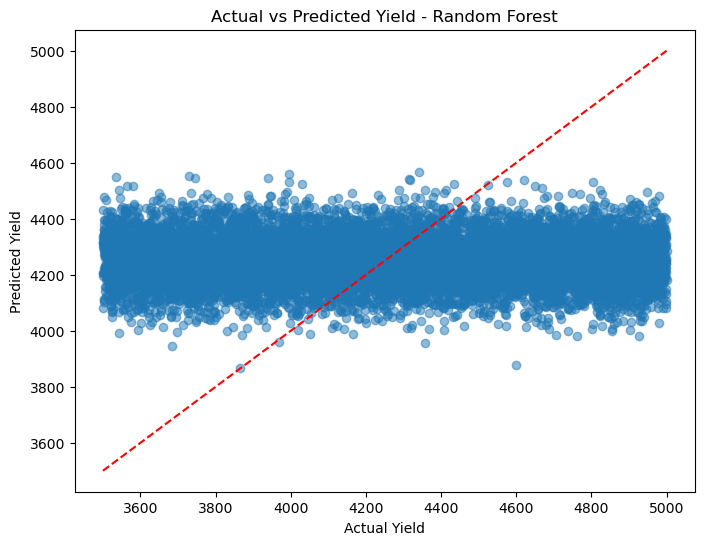

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y,
    predictions["Random Forest"],
    alpha=0.5
)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    "r--"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Yield - Random Forest")
plt.show()

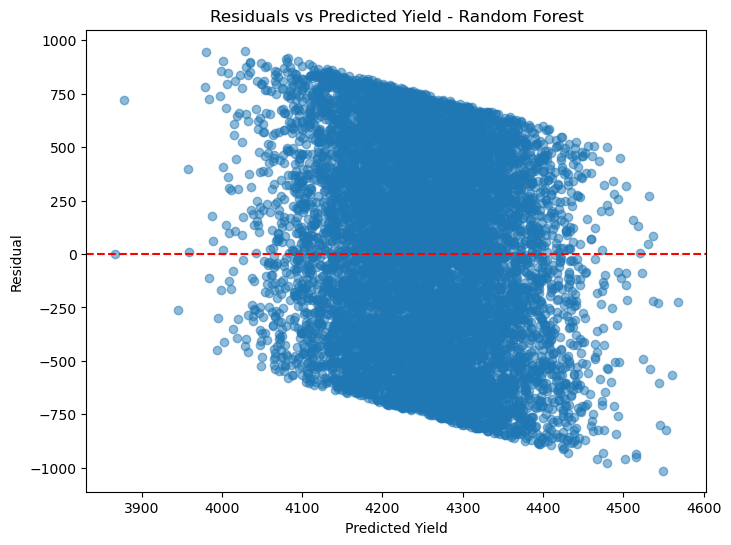

In [4]:
rf_pred = predictions["Random Forest"]
residuals = y - rf_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    rf_pred,
    residuals,
    alpha=0.5
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Yield")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Yield - Random Forest")
plt.show()

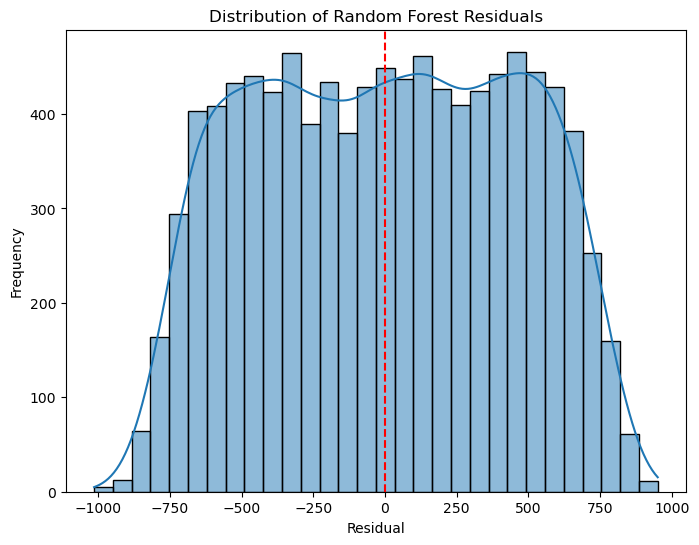

In [5]:
plt.figure(figsize=(8, 6))

sns.histplot(residuals, bins=30, kde=True)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Random Forest Residuals")
plt.show()

In [6]:
import os

output_dir = "stage17_outputs"
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(
    os.path.join(output_dir, "regression_error_metrics.csv"),
    index=False
)

residual_df = pd.DataFrame({
    "Actual_Yield": y.to_numpy(),
    "Dummy_Predicted": predictions["Dummy Regressor"],
    "RF_Predicted": predictions["Random Forest"],
    "RF_Residual": residuals.to_numpy()
})

residual_df.to_csv(
    os.path.join(output_dir, "regression_residuals.csv"),
    index=False
)

print("Stage 17 outputs saved successfully.")

Stage 17 outputs saved successfully.
